# TP4 - Campo magnético de una espira

**Materia:** Electricidad y Magnetismo

**Integrantes:**
* Fernanda Perez
* Tomas Aragusuku
* Jonathan Gomez
* Carla Rocca

## 1. Introducción teórica

Para una espira circular de radio $R$ por la que circula una corriente $I$, la ley de Biot-Savart da el campo magnético sobre el **eje de la espira** (eje $z$, que pasa por su centro y es perpendicular a su plano):

$$\vec{B}(z) = \frac{\mu_0\, N\, I\, R^2}{2\left(R^2 + z^2\right)^{3/2}}\,\hat{z}$$

donde $N$ es la cantidad de vueltas (para una sola espira, $N = 1$) y $\mu_0 = 4\pi \times 10^{-7}\,T\,m/A$. Sobre el eje las componentes radiales se cancelan por simetría, así que el campo es puramente axial y su módulo es la expresión de arriba.

* En el centro ($z = 0$) el campo es máximo: $B_0 = \dfrac{\mu_0 N I}{2R}$.
* Lejos de la espira ($|z| \gg R$) decae como $1/z^3$, igual que el campo de un dipolo magnético.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# Parámetros de la espira (reemplazar por los valores del TP)
mu0 = 4 * np.pi * 1e-7   # Permeabilidad del vacío [T m/A]
R = 0.10                 # Radio de la espira [m]
I = 1.0                  # Corriente [A]
N = 1                    # Cantidad de vueltas

def campo_eje(z):
    """Módulo del campo magnético sobre el eje z de la espira [T]."""
    return mu0 * N * I * R**2 / (2 * (R**2 + z**2) ** 1.5)

B0 = campo_eje(0)
print(f"B en el centro (z = 0)    = {B0*1e6:.2f} uT")
print(f"B en z = R                = {campo_eje(R)*1e6:.2f} uT  ({campo_eje(R)/B0*100:.1f} % de B0)")
print(f"B en z = 3R               = {campo_eje(3*R)*1e6:.3f} uT  ({campo_eje(3*R)/B0*100:.1f} % de B0)")

B en el centro (z = 0)    = 6.28 uT
B en z = R                = 2.22 uT  (35.4 % de B0)
B en z = 3R               = 0.199 uT  (3.2 % de B0)


## 2. Módulo del campo sobre el eje $z$

Se grafica $|B(z)|$ entre $z = -5R$ y $z = 5R$, con el origen en el centro de la espira.

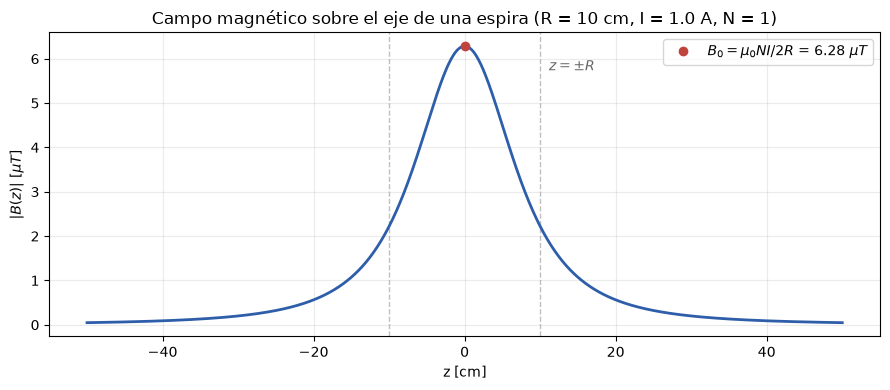

In [11]:
z = np.linspace(-5 * R, 5 * R, 1000)
B = campo_eje(z)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(z * 100, B * 1e6, color="#2E5EAA", linewidth=2)
ax.plot(0, B0 * 1e6, "o", color="#C1443C", label=fr"$B_0 = \mu_0 N I / 2R$ = {B0*1e6:.2f} $\mu T$")

for zr in (-R, R):
    ax.axvline(zr * 100, color="0.75", linestyle="--", linewidth=1, zorder=0)
ax.text(R * 100, B0 * 1e6 * 0.95, r"  $z = \pm R$", color="0.4", va="top")

ax.set_xlabel("z [cm]")
ax.set_ylabel(r"$|B(z)|$ [$\mu T$]")
ax.set_title(f"Campo magnético sobre el eje de una espira (R = {R*100:.0f} cm, I = {I} A, N = {N})")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 3. Análisis

* El campo es máximo en el centro de la espira y simétrico respecto de $z = 0$: $B(z) = B(-z)$.
* En $z = \pm R$ el campo ya cayó a $1/2^{3/2} \approx 35\%$ de $B_0$.
* Para $|z| \gg R$ el campo decae como $1/z^3$, por lo que a pocas veces el radio se vuelve despreciable frente a $B_0$.

## 4. Dos bobinas sobre el eje $z$

Se agrega una segunda bobina igual a la primera (mismo $R$, $I$ y $N$, con la corriente en el mismo sentido), coaxial y ubicada en $z = d$. La primera queda en $z = 0$.

Sobre el eje los campos de ambas bobinas tienen la dirección $\hat{z}$, así que por superposición el módulo del campo total es la suma:

$$B(z) = \frac{\mu_0 N I R^2}{2\left(R^2 + z^2\right)^{3/2}} + \frac{\mu_0 N I R^2}{2\left(R^2 + (z-d)^2\right)^{3/2}}$$

El campo de la segunda bobina es el de la primera desplazado una distancia $d$, es decir `campo_eje(z - d)`.

d = 20.0 cm = 2.00 R
B en el punto medio (z = d/2) = 4.44 uT  (0.71 B0)
B en z = 0                    = 6.85 uT  (1.09 B0)


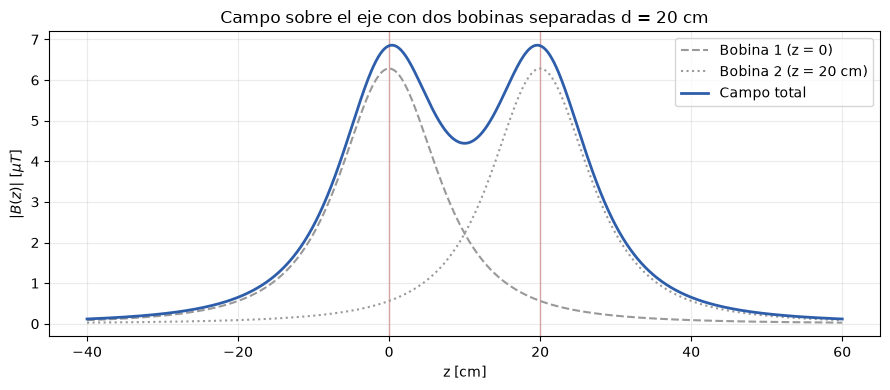

In [15]:
d = 0.2   # Distancia entre las bobinas [m] (d = R es la configuración de Helmholtz)

def campo_dos_bobinas(z, d):
    """Módulo del campo sobre el eje con bobinas en z = 0 y z = d [T]."""
    return campo_eje(z) + campo_eje(z - d)

z2 = np.linspace(-4 * R, d + 4 * R, 1000)
B1 = campo_eje(z2)
B2 = campo_eje(z2 - d)
B_tot = campo_dos_bobinas(z2, d)

B_medio = campo_dos_bobinas(d / 2, d)
print(f"d = {d*100:.1f} cm = {d/R:.2f} R")
print(f"B en el punto medio (z = d/2) = {B_medio*1e6:.2f} uT  ({B_medio/B0:.2f} B0)")
print(f"B en z = 0                    = {campo_dos_bobinas(0, d)*1e6:.2f} uT  ({campo_dos_bobinas(0, d)/B0:.2f} B0)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(z2 * 100, B1 * 1e6, "--", color="0.6", linewidth=1.5, label="Bobina 1 (z = 0)")
ax.plot(z2 * 100, B2 * 1e6, ":", color="0.6", linewidth=1.5, label=f"Bobina 2 (z = {d*100:.0f} cm)")
ax.plot(z2 * 100, B_tot * 1e6, color="#2E5EAA", linewidth=2, label="Campo total")

for zb in (0, d):
    ax.axvline(zb * 100, color="#C1443C", linewidth=1, alpha=0.5, zorder=0)

ax.set_xlabel("z [cm]")
ax.set_ylabel(r"$|B(z)|$ [$\mu T$]")
ax.set_title(f"Campo sobre el eje con dos bobinas separadas d = {d*100:.0f} cm")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### 4.1. Efecto de la distancia entre bobinas

Para ver cómo cambia el campo total con la separación, se grafica para varios valores de $d$. El eje $z$ se centra en el punto medio entre las bobinas ($z - d/2$) para poder comparar las curvas.

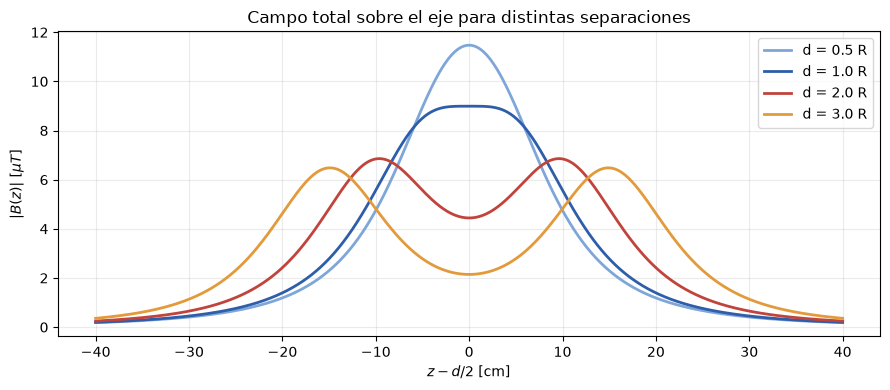

In [16]:
distancias = [0.5 * R, R, 2 * R, 3 * R]
colores = ["#7FA6D9", "#2E5EAA", "#C1443C", "#E39A3B"]

fig, ax = plt.subplots(figsize=(9, 4))
for dk, color in zip(distancias, colores):
    zc = np.linspace(-4 * R, 4 * R, 1000)   # coordenada medida desde el punto medio
    ax.plot(zc * 100, campo_dos_bobinas(zc + dk / 2, dk) * 1e6, color=color, linewidth=2,
            label=f"d = {dk/R:.1f} R")

ax.set_xlabel(r"$z - d/2$ [cm]")
ax.set_ylabel(r"$|B(z)|$ [$\mu T$]")
ax.set_title("Campo total sobre el eje para distintas separaciones")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### 4.2. Análisis

* El campo total es la suma de los campos de cada bobina y es simétrico respecto del punto medio $z = d/2$.
* Si las bobinas están **muy separadas** ($d \gtrsim 2R$), el campo total muestra dos máximos (uno en cada bobina) con un mínimo entre ellas, porque cada bobina aporta poco en la posición de la otra.
* Si están **muy juntas** ($d < R$), los dos picos se funden en uno solo, más alto, con máximo en el punto medio.
* Para $d = R$ (**bobinas de Helmholtz**) se pasa de un caso al otro: en el punto medio se anulan la primera y la segunda derivada de $B(z)$, y el campo queda **casi uniforme** en una región amplia entre las bobinas. Por eso esta configuración se usa para generar campos magnéticos homogéneos. En ese punto vale $B = \left(\tfrac{4}{5}\right)^{3/2} \dfrac{\mu_0 N I}{R} \approx 1,43\,B_0$.